# Module 2: FSHD Preliminary Project Check-In

## Project Goal:

**Does MRI fat fraction detect FSHD progression more consistently than dorsiflexion muscle strength?**

FSHD causes variable muscle weakness, which makes it difficult to select measures that reliably track progression in clinical trials. We will compare changes in tibialis anterior (TA) MRI fat fraction and dorsiflexion quantitative muscle testing (QMT) using the same participants, leg, and comparison times. We will define consistency as the proportion of participants showing the expected progression in both successive intervals: increasing fat fraction or decreasing strength. The final analysis will support a recommendation for MRI, strength, or both as exploratory endpoints, while recognizing that an imaging change alone does not establish a benefit in patient function.

## Disease Background:

ChatGPT assisted with drafting these four entries; factual sources are linked below (see AI Usage Statement).

- **Prevalence & incidence:** A Dutch population study estimated symptomatic FSHD prevalence at **12 per 100,000 people** and incidence at **0.3 newly diagnosed cases per 100,000 person-years**. These estimates used diagnoses from 2001-2010 and adjustment for unregistered cases, so they should not be treated as current worldwide rates. ([Deenen et al., 2014](https://pubmed.ncbi.nlm.nih.gov/25122204/))

- **Symptoms:** FSHD commonly weakens facial muscles, muscles that stabilize the shoulder blades, and muscles that lift the foot. This can cause difficulty with facial movements, raising the arms, and walking because of foot drop, with severity varying between patients. ([Preston & Wang, GeneReviews](https://pubmed.ncbi.nlm.nih.gov/20301616/))

- **Diagnosis:** Diagnosis combines the characteristic weakness pattern with molecular testing. FSHD1 involves a shortened D4Z4 repeat array on a permissive chromosome 4 background, whereas FSHD2 involves reduced D4Z4 methylation on that background and may require testing genes such as SMCHD1. ([Preston & Wang, GeneReviews](https://pubmed.ncbi.nlm.nih.gov/20301616/))

- **Standard of care treatments (& reimbursement):** Supportive care includes physical therapy, an appropriate exercise program, ankle-foot orthoses, and pain management. Selected patients may need scapular fixation surgery or breathing support. As one U.S. reimbursement example, Original Medicare Part B covers medically necessary outpatient physical therapy for eligible patients, generally with 20% coinsurance after the deductible. ([GeneReviews](https://pubmed.ncbi.nlm.nih.gov/20301616/); [Medicare coverage](https://www.medicare.gov/coverage/physical-therapy-services))

- **Disease progression & prognosis:** FSHD usually progresses slowly, but the rate and pattern of muscle weakness can vary significantly between individuals. The disease can also affect the left and right sides of the body differently, with some muscles weakening faster than others. Over time, muscle tissue gradually degenerates and is replaced by fat, reducing strength and mobility. However, patients may compensate for muscle weakness by adjusting their movements, making physical decline harder to detect. This makes it important to identify reliable measurements that can track disease progression over time. (BME 2315 Module 2, Lecture 1)

- **Biological mechanisms**  FSHD is primarily caused by abnormal activation of the DUX4 gene in skeletal muscle cells. In FSHD1, the most common form, a shortened D4Z4 repeat region on chromosome 4 allows DUX4 to become active when it normally should remain suppressed. This causes muscle cell damage and progressive degeneration. As healthy muscle fibers are lost, fat gradually replaces some of the muscle tissue, reducing its ability to produce force. MRI can detect this fat replacement through measurements such as fat fraction, providing a way to observe structural muscle changes even when physical performance remains relatively stable. (BME 2315 Module 2, Lecture 1 and 2)

- **Clinical trials/next-gen therapies:** There is currently no approved treatment that stops or reverses FSHD progression, but researchers are developing therapies that target DUX4 activity to reduce muscle damage. One example is losmapimod, an experimental drug designed to reduce DUX4 expression. Although earlier trials showed promising results, its Phase 3 REACH trial did not demonstrate a significant improvement in its primary functional outcome, leading to the discontinuation of its development for FSHD. This highlights the difficulty of measuring treatment effectiveness, especially when disease progression is slow. Researchers are therefore investigating MRI fat fraction, muscle strength, and functional assessments as potential clinical trial endpoints. ([FSHD Society, 2024](https://www.fshdsociety.org/2024/09/12/fulcrum-halts-losmapimod-development/); BME 2315 Module 2, Lecture 1)

## Data Set:

- **The subject and visit/timepoint(s) analyzed:** `Module2_FSHD_Dataset.csv` contains 34 participants with baseline, Year 1, and Year 2 fields, but some observations are missing. Recorded follow-up times range from 11.15-24.30 months for Year 1 and 22.13-42.77 months for Year 2. This MRI demonstration uses **UW_0020, left TA, TP1, slice 4**; TP2 is available, but the supplied documentation does not give the elapsed time between MRI visits or confirm a match to a CSV participant ID.

- **The tibialis anterior MRI data:** The teaching sample contains eight cross-sectional images of the left TA at each of two visits, with each supplied image measuring 266 rows by 224 columns. The underlying study used Dixon MRI to separate water and fat signals, while the course package supplies extracted images ready for analysis. We will demonstrate the calculation on one slice before extending it to the remaining locations.

- **The water-image and fat-image files:** Matched NumPy files, such as `TP1_slice_04_water.npy` and `TP1_slice_04_fat.npy`, contain the water and fat signals for the same image section. Each array covers the half-section containing the TA and retains surrounding tissues and background. `slice_info.csv` pairs the files, and fat fraction must be calculated from their signals because no precomputed fat-fraction image is supplied.

- **The tibialis anterior segmentation mask:** Each image pair has a supplied binary mask, such as `TP1_slice_04_mask.npy`, with 1 marking TA pixels and 0 marking other pixels. The metadata records source segmentation label 59, but the exported mask is binary and should be tested for nonzero values. We will use these supplied boundaries rather than create a new segmentation; the teaching README does not specify how the original boundaries were drawn or corrected.

- **The sampled locations along the muscle:** The MRI dataset contains eight cross-sectional images taken at different locations along the tibialis anterior (TA) muscle for each visit (TP1 and TP2). These locations allow us to measure how fat fraction varies throughout the muscle rather than relying on a single image. The locations are not necessarily equally spaced, so we will use the distances provided in slice_info.csv to compare measurements along the muscle.

- **The meaning and units of the image signals:** The water and fat images contain MRI signal intensities representing the relative amounts of water and fat within the tissue. We can calculate fat fraction by dividing the fat signal by the combined water and fat signals and multiplying by 100. This produces a percentage representing the relative fat signal in each pixel.

- **The clinical, biomarker, or functional measurements included in the dataset:** The dataset includes MRI measurements such as fat fraction (ff), fat fraction variation (fvar), and STIR measurements (stir_quant). It also includes biological information such as DUX4 signature values and D4Z4 repeat length. Clinical and functional measurements include dorsiflexion muscle strength (dorsiflexion_qmt), Timed Up and Go (tug_time), walking tests (wr_10), stair ascent and descent tests, and clinical severity scores. 
- **The source of the data:** The dataset comes from a 2024 study by Wong et al., titled Regional and bilateral MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression. The study included 34 patients with FSHD, recruited from the University of Washington, University of Rochester, and University of Kansas medical centers. Researchers collected MRI measurements of the tibialis anterior muscles, muscle strength measurements, and muscle biopsies to investigate disease progression and identify potential biomarkers for clinical trials. ([Wong et al., 2024](https://doi.org/10.1093/hmg/ddae007))

## MRI Data Analysis Methodology:

We have started by loading one MRI sample. The remaining analysis is planned using the workflow in the course example notebook [4].

### Load the files and identify the TA

We use pandas to read the file list and NumPy to load matching water, fat, and mask arrays for TP1 slice 4. The mask selects TA pixels, and this first check confirms matching image dimensions and counts the selected muscle pixels.

To run the code, unzip `FSHD_MRI_data.zip` beside this notebook and keep its folder structure.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the extracted MRI teaching folder. Only this path setup is different
# from the instructor's example notebook.
candidates = [
    Path("FSHD_TA_MRI_data_0020_TP1_TP2"),
    Path("FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2"),
    Path("data/FSHD_TA_MRI_data_0020_TP1_TP2"),
]
DATA_DIR = next((p for p in candidates if (p / "slice_info.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Extract FSHD_TA_MRI_data_0020_TP1_TP2 beside this notebook "
        "or inside FSHD_MRI_data/ or data/, and rerun this cell."
    )
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest


row = manifest[manifest["timepoint"] == "TP1"].iloc[3]  # representative mid-muscle slice

water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

print("TA muscle pixels:", int(mask.sum()))
print("Pixels in the supplied image region:", mask.size)



Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360
TA muscle pixels: 360
Pixels in the supplied image region: 59584


### Calculate fat fraction

We will calculate **fat fraction (%) = 100 x fat / (water + fat)** for each valid pixel. We will exclude invalid signals and zero denominators, then compare values across the supplied image region with values inside the TA mask.


Whole supplied image region — mean: 48.6%
Whole supplied image region — minimum: 0.0%
Whole supplied image region — maximum: 100.0%

TA muscle only — mean: 29.9%
TA muscle only — minimum: 0.5%
TA muscle only — maximum: 90.7%


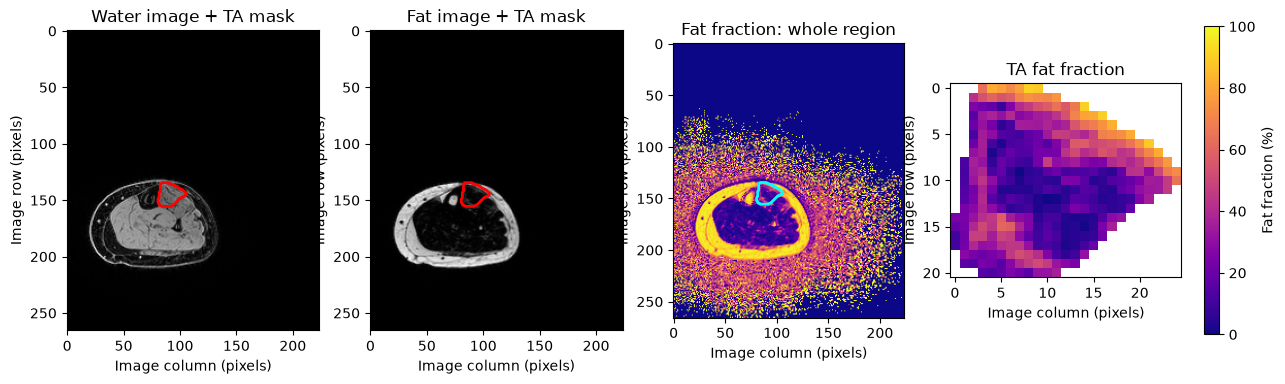

In [3]:
denominator = water + fat
valid_pixels = denominator > 0

fat_fraction = np.divide(
    fat,
    denominator,
    out=np.zeros_like(fat, dtype=float),
    where=valid_pixels
) * 100

# Keep the whole supplied image region for the first analysis.
fat_fraction_full = fat_fraction.copy()

# Then apply the TA mask for the muscle-specific analysis.
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~(mask & valid_pixels)] = np.nan

whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

print(f"Whole supplied image region — mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region — minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region — maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only — mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only — minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only — maximum: {np.max(muscle_values):.1f}%")



# Find the bounding box of the TA mask
y_pixels, x_pixels = np.where(mask)

y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1

# Crop the TA-specific fat-fraction map
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Water image with TA mask outline
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[0].set_title("Water image + TA mask")

# Fat image with TA mask outline
axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

# Fat fraction for the whole supplied image region
whole_image = axes[2].imshow(
    fat_fraction_full,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

# Zoomed-in fat fraction for the TA only
ta_image = axes[3].imshow(
    fat_fraction_TA,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[3].set_title("TA fat fraction")

for ax in axes:
    ax.set_xlabel("Image column (pixels)")
    ax.set_ylabel("Image row (pixels)")

# Both fat-fraction plots use the same 0–100% scale
fig.colorbar(
    ta_image,
    ax=axes[2:],
    fraction=0.046,
    pad=0.04,
    label="Fat fraction (%)"
)

plt.show()



### Summarize the distribution 

We will use a histogram to examine the TA fat-fraction distribution and report its mean, median, standard deviation, and valid muscle pixel count. Figures will have labeled axes, units, and a short caption explaining what they show.


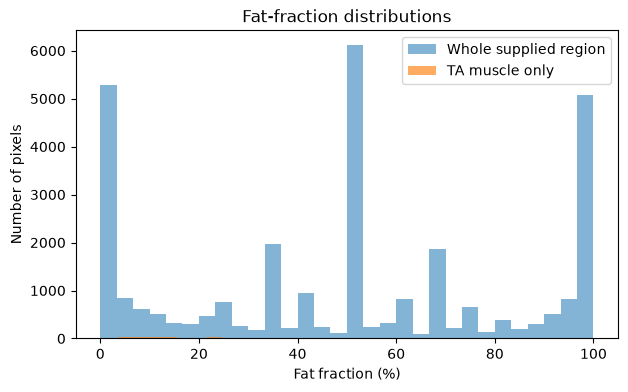

Total pixels inside TA mask: 360


,Region,Mean fat fraction (%),Median fat fraction (%),Std. dev. (percentage points),Number of valid pixels
0,Whole supplied image region,48.58,50.00,34.43,30797
1,TA muscle only,29.93,25.37,21.58,360


In [4]:
plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=30, alpha=0.55, label="Whole supplied region")
plt.hist(muscle_values, bins=30, alpha=0.65, label="TA muscle only")
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distributions")
plt.legend()
plt.show()

# Summarize the same two sets of pixels used in the histogram.
summary_stats = pd.DataFrame([
    {
        "Region": "Whole supplied image region",
        "Mean fat fraction (%)": np.mean(whole_image_values),
        "Median fat fraction (%)": np.median(whole_image_values),
        "Std. dev. (percentage points)": np.std(whole_image_values),
        "Number of valid pixels": len(whole_image_values),
    },
    {
        "Region": "TA muscle only",
        "Mean fat fraction (%)": np.mean(muscle_values),
        "Median fat fraction (%)": np.median(muscle_values),
        "Std. dev. (percentage points)": np.std(muscle_values),
        "Number of valid pixels": len(muscle_values),
    },
])
print("Total pixels inside TA mask:", int(mask.sum()))
display(summary_stats.round(2))





### Compare locations and visits 

We will repeat the calculation at the eight sampled locations and plot mean TA fat fraction against the recorded distance along the muscle in millimeters. We will compare TP1 and TP2 at matching relative positions, assuming these represent approximately the same muscle regions.


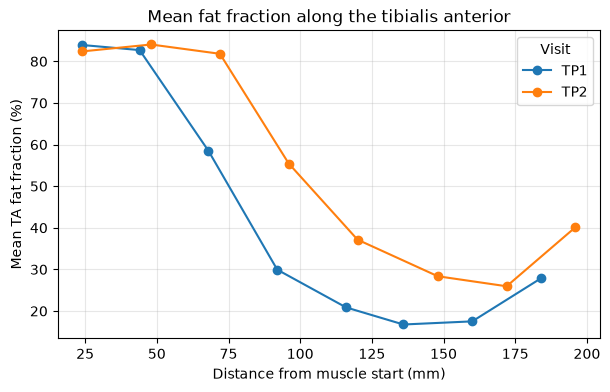

Saved TA_fat_fraction_summary.csv


In [5]:
def calculate_fat_fraction(water, fat, mask):
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(
        fat,
        denominator,
        out=np.zeros_like(fat, dtype=float),
        where=denominator > 0
    ) * 100
    result[~(mask & (denominator > 0))] = np.nan
    return result

analysis_timepoint = "TP1"  # analyze one visit at a time
analysis_manifest = manifest[manifest["timepoint"] == analysis_timepoint]
results = []

for _, row in analysis_manifest.iterrows():
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)

    results.append({
        "subject": row["subject"],
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "percent_along_muscle": row["percent_along_muscle"],
        "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
    })

results_df = pd.DataFrame(results)
results_df


def summarize_visit(timepoint):
    visit_results = []
    visit_manifest = manifest[manifest["timepoint"] == timepoint]

    for _, row in visit_manifest.iterrows():
        water = np.load(DATA_DIR / row["water_file"])
        fat = np.load(DATA_DIR / row["fat_file"])
        mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
        ff = calculate_fat_fraction(water, fat, mask)

        visit_results.append({
            "timepoint": timepoint,
            "slice_id": row["slice_id"],
            "percent_along_muscle": row["percent_along_muscle"],
            "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
            "mean_fat_fraction_percent": np.nanmean(ff),
        })

    return pd.DataFrame(visit_results)

profiles_df = pd.concat(
    [summarize_visit("TP1"), summarize_visit("TP2")],
    ignore_index=True
)

plt.figure(figsize=(7, 4))
for timepoint, group in profiles_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")
    plt.plot(
        group["distance_from_muscle_start_mm"],
        group["mean_fat_fraction_percent"],
        marker="o",
        label=timepoint
    )
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()


output_file = Path("TA_fat_fraction_summary.csv")
results_df.to_csv(output_file, index=False)
print(f"Saved {output_file}")



### Compare progression over time 

For the cohort analysis, we will compare MRI fat fraction and dorsiflexion strength for the same participants and leg using actual visit times. If needed, linear interpolation will estimate measurements at common times, using recorded months as x and fat fraction or strength as y. This assumes linear change between measured visits and will only be used when valid observations bracket the target time [5].

## Interpolation Analysis:

We used interpolation to compare MRI fat fraction and dorsiflexion strength at common times because participants did not return at exactly the same number of months.

- **Variable used to define location:** The MRI profile uses `distance_from_muscle_start_mm` to show where each slice falls along the TA. For the interpolation below, our group instead used months after baseline to compare visits; the code does not estimate fat fraction at a new location along the muscle.

- **Sampled inputs:** We used each participant's baseline, Year 1, and Year 2 fat-fraction and strength measurements for each leg, together with their recorded visit times. Baseline was 0 months, while Year 1 ranged from 11.15 to 24.30 months and Year 2 ranged from 22.13 to 42.77 months.

- **Interpolation method and Python code:** The code below uses `np.interp` to estimate T1 = 11.15 months from baseline and Year 1, then `np.polyfit(..., 2)` and `np.polyval` to estimate T2 = 22.13 months from all three visits. This places participants on the same timeline before comparing changes in fat fraction and strength.

- **Measured values and interpolated estimates:** The plot below shows subject 1-0019's measured values as black points, with the linear estimate shown by a solid line and the quadratic estimate shown by a dashed line. The vertical lines mark 11.15 and 22.13 months, where the corresponding curves provide the estimates used in the analysis.

- **Why these are estimates:** Interpolation calculates values from measurements already collected rather than collecting another MRI scan or strength test. This means that a value between visits depends on the fitted line or curve and may differ from what would have been measured at that time.

- **Assumptions between sampled points:** Linear interpolation assumes a constant rate of change between baseline and Year 1. Quadratic interpolation assumes that one smooth curve can describe the change across all three visits, although actual FSHD progression may not follow that pattern.

- **Interpolation or extrapolation:** Both target times had to fall within the visit range used for that calculation, so the code does not extrapolate beyond a participant's available measurements. Missing values or invalid visit sequences produce `NaN`, and only participants with both outcomes at both target times enter the paired comparison.

- **Limitations and uncertainty:** Only three visits define the quadratic curve, so fitting those points does not confirm that it follows the actual change between visits. Measurement error and the different methods at T1 and T2 can affect the comparison, and the curve can exceed the measured values even within the observed time range. The code also does not calculate uncertainty intervals for the estimates.


### Interpolation code

The following cells contain our group's interpolation analysis.


In [5]:
"""FSHD Module 2: subject-level time interpolation."""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
CSV = next((p for p in (BASE/'Module2_FSHD_Dataset.csv', BASE/'Module2_FSHD_Dataset(1).csv') if p.exists()), None)
if CSV is None:
    raise FileNotFoundError('Put Module2_FSHD_Dataset.csv in the same folder as this script/notebook.')
df = pd.read_csv(CSV)
T1 = float(df['lag_months_y1'].min())
T2 = float(df['lag_months_y2'].min())
print(f'Common visit times: T1={T1:.2f} months, T2={T2:.2f} months')

Common visit times: T1=11.15 months, T2=22.13 months


In [6]:

measures = {
    'fat_fraction': {'R':['ff_baseline_R','ff_y1_R','ff_y2_R'], 'L':['ff_baseline_L','ff_y1_L','ff_y2_L']},
    'dorsiflexion_strength': {'R':['dorsiflexion_qmt_R_baseline','dorsiflexion_qmt_R_y1','dorsiflexion_qmt_R_y2'],
                             'L':['dorsiflexion_qmt_L_baseline','dorsiflexion_qmt_L_y1','dorsiflexion_qmt_L_y2']}
}

def linear_interpolate(t, values, target):
    """Linear interpolation on two real, finite bracketing measurements."""
    t, values = np.asarray(t, dtype=float), np.asarray(values, dtype=float)
    good = np.isfinite(t) & np.isfinite(values)
    t, values = t[good], values[good]
    if len(t) != 2 or t[0] >= t[1] or not(t[0] <= target <= t[1]):
        return np.nan
    return float(np.interp(target, t, values))

def quadratic_interpolate(t, values, target):
    """Degree-2 interpolating polynomial through all 3 real visits (no extrapolation)."""
    t, values = np.asarray(t, dtype=float), np.asarray(values, dtype=float)
    if not(np.all(np.isfinite(t)) and np.all(np.isfinite(values))):
        return np.nan
    if not(t[0] < t[1] < t[2] and t[0] <= target <= t[2]):
        return np.nan
    return float(np.polyval(np.polyfit(t, values, 2), target))

records=[]
for _, sub in df.iterrows():
    times = [sub['lag_months_baseline'], sub['lag_months_y1'], sub['lag_months_y2']]
    for measure, sides in measures.items():
        for side, cols in sides.items():
            y = [sub[c] for c in cols]
            v1 = linear_interpolate(times[:2], y[:2], T1)
            v2 = quadratic_interpolate(times, y, T2)
            # Linear-at-T2 retained as a sensitivity check (optional).
            v2_linear = linear_interpolate(times[1:], y[1:], T2)
            records.append({'subject_id':sub['subject_id'], 'side':side,
                            'measure':measure, 'baseline':y[0], 'year1_actual':y[1],
                            'year2_actual':y[2], 't1_linear':v1,
                            't2_quadratic':v2, 't2_linear_sensitivity':v2_linear,
                            'change_t1_to_t2':v2-v1 if np.isfinite(v1) and np.isfinite(v2) else np.nan})
results = pd.DataFrame(records)
results.to_csv(BASE/'FSHD_interpolated_all_sides.csv', index=False)
print('\nAvailable interpolation values (out of 34 subjects per side):')
print(results.groupby(['measure','side'])[['t1_linear','t2_quadratic','change_t1_to_t2']].count().to_string())

# For a genuinely subject-level comparison, average left and right only if BOTH
# measures are available in a given side at both targets; pairing avoids unequal cohorts.
wide = results.pivot(index=['subject_id','side'], columns='measure', values=['t1_linear','t2_quadratic'])
wide.columns=['_'.join(c) for c in wide.columns]
paired = wide.dropna().reset_index()
subject = paired.groupby('subject_id',as_index=False).mean(numeric_only=True)
for measure in measures:
    subject[f'{measure}_T1'] = subject[f't1_linear_{measure}']
    subject[f'{measure}_T2'] = subject[f't2_quadratic_{measure}']
    subject[f'{measure}_absolute_change'] = subject[f'{measure}_T2']-subject[f'{measure}_T1']
    subject[f'{measure}_percent_change'] = np.where(
        subject[f'{measure}_T1'].abs()>1e-10,
        100*subject[f'{measure}_absolute_change']/subject[f'{measure}_T1'], np.nan)
subject.to_csv(BASE/'FSHD_interpolated_subjects_paired.csv',index=False)
print(f'\nParticipants with both outcomes for paired analysis: {len(subject)} / {df.subject_id.nunique()}')
for measure in measures:
    x = subject[f'{measure}_percent_change'].dropna()
    print(f'{measure}: mean percent change={x.mean():.2f}%, SD={x.std(ddof=1):.2f}%, N={len(x)}')




Available interpolation values (out of 34 subjects per side):
                            t1_linear  t2_quadratic  change_t1_to_t2
measure               side                                          
dorsiflexion_strength L            25            21               21
                      R            25            21               21
fat_fraction          L            30            24               24
                      R            30            24               24

Participants with both outcomes for paired analysis: 21 / 34
fat_fraction: mean percent change=4.91%, SD=11.87%, N=21
dorsiflexion_strength: mean percent change=0.85%, SD=14.80%, N=21


**Measured visits and interpolation curves**


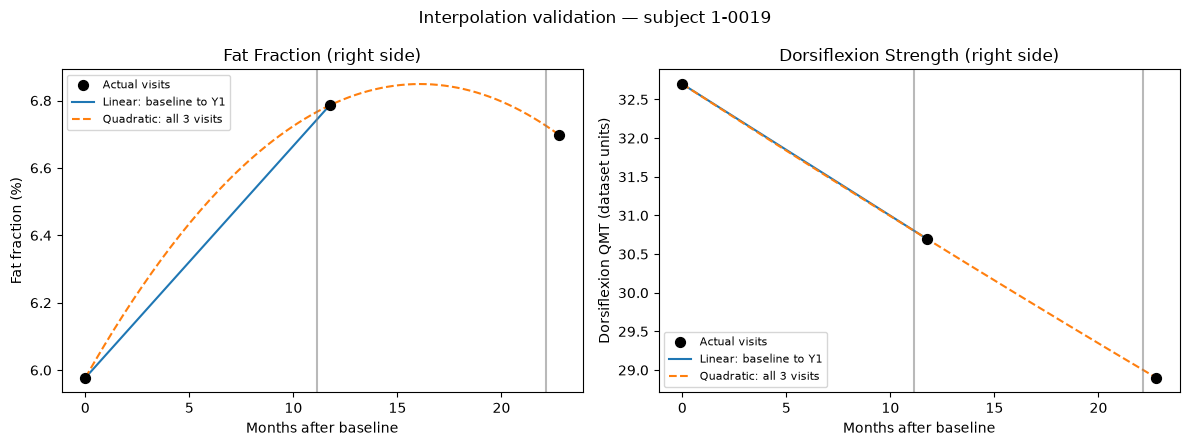

In [7]:
# Validation chart: one person, both visits, actual data and fitted curves.
# Generated with matplotlib; saved separately for pasting into the main notebook.
from matplotlib.lines import Line2D
valid_ids = subject['subject_id'].tolist()
if valid_ids:
    pid=valid_ids[0]
    original=df.loc[df.subject_id==pid].iloc[0]
    xx=np.array([original['lag_months_baseline'],original['lag_months_y1'],original['lag_months_y2']],dtype=float)
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    for ax,(measure, cols) in zip(axes,[(m,measures[m]['R']) for m in measures]):
        yy=np.array([original[c] for c in cols],dtype=float)
        ax.scatter(xx,yy,s=50,color='black',label='Actual visits',zorder=4)
        dense=np.linspace(xx[0],xx[-1],150)
        ax.plot(dense[dense<=xx[1]],np.interp(dense[dense<=xx[1]],xx[:2],yy[:2]),label='Linear: baseline to Y1')
        ax.plot(dense,np.polyval(np.polyfit(xx,yy,2),dense),label='Quadratic: all 3 visits',linestyle='--')
        ax.axvline(T1,color='gray',alpha=.55);ax.axvline(T2,color='gray',alpha=.55)
        ax.set(xlabel='Months after baseline',ylabel='Fat fraction (%)' if measure=='fat_fraction' else 'Dorsiflexion QMT (dataset units)',title=f'{measure.replace("_"," ").title()} (right side)')
        ax.legend(fontsize=8)
    fig.suptitle(f'Interpolation validation — subject {pid}')
    fig.tight_layout()
    fig.savefig(BASE/'FSHD_interpolation_validation.png',dpi=170,bbox_inches='tight')
    plt.show()


The estimates at T1 and T2 are calculated separately for each leg, then eligible legs are averaged so each participant contributes one value per outcome. Both legs were eligible for all 21 participants in the final comparison.


**Percentage-change charts 1 and 2**

Figures 1 and 2 compare each participant's relative change from T1 to T2, with increasing fat fraction and decreasing strength representing the expected progression. The paired t-tests use the estimated T1 and T2 values, while the mean and SD summarize relative percentage changes. Figure 1's labels use the code's mean/SD cutoff of 0.3 as a descriptive guide; they do not establish that the variation in strength is only measurement noise.


Common visit times: T1=11.15 months, T2=22.13 months
Participants with both outcomes for paired analysis: 21 / 34
              measure                 label  n  mean_pct  sd_pct  mean_over_sd  p_value  T1_mean  T2_mean
         fat_fraction      MRI fat fraction 21    4.9061 11.8746        0.4132   0.0105  13.8434  14.7183
dorsiflexion_strength Dorsiflexion strength 21    0.8469 14.7982        0.0572   0.5751  16.7644  17.0268


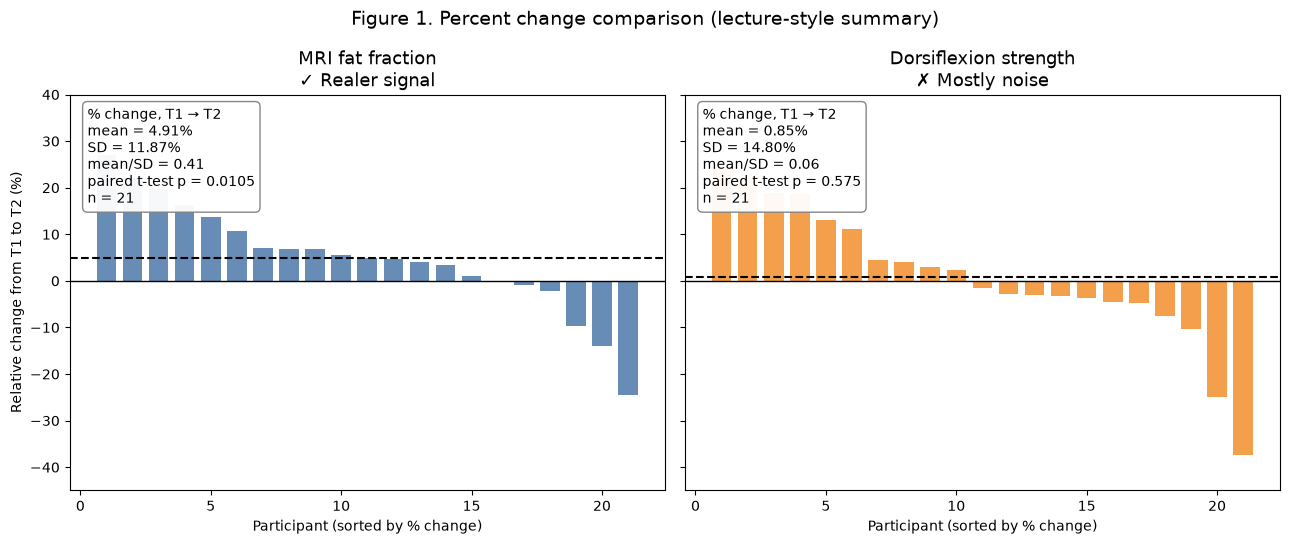

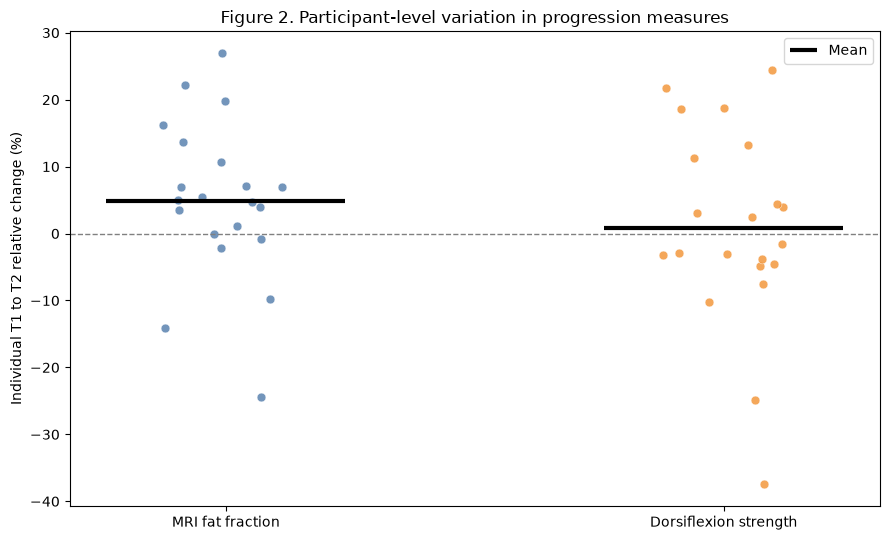

In [8]:

"""FSHD Module 2: interpolation + charts 1 and 2 .
Run beside Module2_FSHD_Dataset.csv.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE = Path.cwd()
CSV = next((p for p in (BASE/'Module2_FSHD_Dataset.csv', BASE/'Module2_FSHD_Dataset(1).csv') if p.exists()), None)

df = pd.read_csv(CSV)
T1 = float(df['lag_months_y1'].min())
T2 = float(df['lag_months_y2'].min())
print(f'Common visit times: T1={T1:.2f} months, T2={T2:.2f} months')

measures = {
    'fat_fraction': {'R':['ff_baseline_R','ff_y1_R','ff_y2_R'], 'L':['ff_baseline_L','ff_y1_L','ff_y2_L']},
    'dorsiflexion_strength': {'R':['dorsiflexion_qmt_R_baseline','dorsiflexion_qmt_R_y1','dorsiflexion_qmt_R_y2'],
                             'L':['dorsiflexion_qmt_L_baseline','dorsiflexion_qmt_L_y1','dorsiflexion_qmt_L_y2']}
}
labels = {'fat_fraction':'MRI fat fraction', 'dorsiflexion_strength':'Dorsiflexion strength'}
colors = {'fat_fraction':'#4C78A8', 'dorsiflexion_strength':'#F28E2B'}

def linear_interpolate(t, values, target):
    t, values = np.asarray(t, dtype=float), np.asarray(values, dtype=float)
    good = np.isfinite(t) & np.isfinite(values)
    t, values = t[good], values[good]
    if len(t) != 2 or t[0] >= t[1] or not (t[0] <= target <= t[1]):
        return np.nan
    return float(np.interp(target, t, values))

def quadratic_interpolate(t, values, target):
    t, values = np.asarray(t, dtype=float), np.asarray(values, dtype=float)
    if not (np.all(np.isfinite(t)) and np.all(np.isfinite(values))):
        return np.nan
    if not (t[0] < t[1] < t[2] and t[0] <= target <= t[2]):
        return np.nan
    return float(np.polyval(np.polyfit(t, values, 2), target))

records=[]
for _, sub in df.iterrows():
    times = [sub['lag_months_baseline'], sub['lag_months_y1'], sub['lag_months_y2']]
    for measure, sides in measures.items():
        for side, cols in sides.items():
            y = [sub[c] for c in cols]
            v1 = linear_interpolate(times[:2], y[:2], T1)
            v2 = quadratic_interpolate(times, y, T2)
            records.append({'subject_id':sub['subject_id'], 'side':side, 'measure':measure,
                            't1_linear':v1, 't2_quadratic':v2})
results = pd.DataFrame(records)

wide = results.pivot(index=['subject_id','side'], columns='measure', values=['t1_linear','t2_quadratic'])
wide.columns = ['_'.join(c) for c in wide.columns]
paired = wide.dropna().reset_index()
subject = paired.groupby('subject_id', as_index=False).mean(numeric_only=True)
for measure in measures:
    subject[f'{measure}_T1'] = subject[f't1_linear_{measure}']
    subject[f'{measure}_T2'] = subject[f't2_quadratic_{measure}']
    subject[f'{measure}_absolute_change'] = subject[f'{measure}_T2'] - subject[f'{measure}_T1']
    subject[f'{measure}_percent_change'] = np.where(
        subject[f'{measure}_T1'].abs() > 1e-10,
        100 * subject[f'{measure}_absolute_change'] / subject[f'{measure}_T1'],
        np.nan
    )

print(f'Participants with both outcomes for paired analysis: {len(subject)} / {df.subject_id.nunique()}')

stat_rows=[]
for measure in ['fat_fraction','dorsiflexion_strength']:
    t1 = subject[f'{measure}_T1'].to_numpy(dtype=float)
    t2 = subject[f'{measure}_T2'].to_numpy(dtype=float)
    pct = subject[f'{measure}_percent_change'].to_numpy(dtype=float)
    ok = np.isfinite(t1) & np.isfinite(t2) & np.isfinite(pct)
    t1, t2, pct = t1[ok], t2[ok], pct[ok]
    delta = t2 - t1
    t_stat, p_val = stats.ttest_rel(t2, t1) if len(delta) >= 2 else (np.nan, np.nan)
    stat_rows.append({
        'measure': measure,
        'label': labels[measure],
        'n': len(delta),
        'mean_pct': np.mean(pct),
        'sd_pct': np.std(pct, ddof=1),
        'mean_over_sd': np.mean(pct) / np.std(pct, ddof=1) if np.std(pct, ddof=1) > 0 else np.nan,
        'p_value': p_val,
        'T1_mean': np.mean(t1),
        'T2_mean': np.mean(t2)
    })
stat_table = pd.DataFrame(stat_rows)
print(stat_table.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

# ----- Figure 1: lecture-style percent change summary -----
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
all_vals = []
for measure in ['fat_fraction', 'dorsiflexion_strength']:
    vals = subject[f'{measure}_percent_change'].dropna().to_numpy(dtype=float)
    all_vals.extend(vals.tolist())
ymin = min(-30, np.floor(min(all_vals)/5)*5 - 5)
ymax = max(30, np.ceil(max(all_vals)/5)*5 + 10)

for ax, measure in zip(axes, ['fat_fraction', 'dorsiflexion_strength']):
    vals = subject[f'{measure}_percent_change'].dropna().to_numpy(dtype=float)
    vals = np.sort(vals)[::-1]
    x = np.arange(1, len(vals)+1)
    ax.bar(x, vals, color=colors[measure], alpha=0.85, width=0.75)
    ax.axhline(0, color='black', linewidth=1)
    ax.axhline(np.mean(vals), color='black', linestyle='--', linewidth=1.5)
    row = stat_table.loc[stat_table['measure'] == measure].iloc[0]
    signal_text = 'Realer signal' if abs(row['mean_over_sd']) >= 0.3 else 'Mostly noise'
    marker = '✓' if abs(row['mean_over_sd']) >= 0.3 else '✗'
    ax.set_title(f"{labels[measure]}\n{marker} {signal_text}", fontsize=13)
    ax.set_xlabel('Participant (sorted by % change)')
    ax.set_ylim(ymin, ymax)
    summary_text = (
        f"% change, T1 → T2\n"
        f"mean = {row['mean_pct']:.2f}%\n"
        f"SD = {row['sd_pct']:.2f}%\n"
        f"mean/SD = {row['mean_over_sd']:.2f}\n"
        f"paired t-test p = {row['p_value']:.3g}\n"
        f"n = {int(row['n'])}"
    )
    ax.text(0.03, 0.97, summary_text, transform=ax.transAxes, va='top', ha='left',
            fontsize=10, bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='gray', alpha=0.95))
axes[0].set_ylabel('Relative change from T1 to T2 (%)')
fig.suptitle('Figure 1. Percent change comparison (lecture-style summary)', fontsize=14)
fig.tight_layout()
plt.show()

# ----- Figure 2: individual percent changes -----
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, measure in enumerate(['fat_fraction', 'dorsiflexion_strength']):
    vals = subject[f'{measure}_percent_change'].to_numpy(dtype=float)
    vals = vals[np.isfinite(vals)]
    jitter = np.random.default_rng(2315+i).uniform(-.13, .13, len(vals))
    ax.scatter(i + jitter, vals, alpha=.78, s=40, color=colors[measure], edgecolors='white', linewidths=.4)
    ax.hlines(np.mean(vals), i-.24, i+.24, color='black', linewidth=3, label='Mean' if i == 0 else None)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xticks([0, 1], [labels['fat_fraction'], labels['dorsiflexion_strength']])
ax.set_ylabel('Individual T1 to T2 relative change (%)')
ax.set_title('Figure 2. Participant-level variation in progression measures')
ax.legend()
fig.tight_layout()
plt.show()


## Conclusions:

- **Which measures changed most consistently:** MRI fat fraction showed the clearer progression trend from T1 to T2, with a mean relative increase of 4.91% (SD = 11.87%), while strength increased by 0.85% (SD = 14.80%) instead of showing the expected decline. The paired t-tests of the estimated values gave p = 0.0105 for fat fraction and p = 0.5751 for strength. This suggests MRI captured change more clearly in this sample, although it does not prove that MRI is statistically more sensitive than strength.

- **Sensitivity across muscle locations and visits:** MRI fat fraction showed differences along the TA, with higher values near the muscle start than in the middle of the displayed profile. TP2 was also generally higher than TP1, although the sampled distances differed between visits. Strength was not measured at individual slice locations, so we could not make the same spatial comparison.

- **Use as biomarkers or exploratory endpoints:** Our results support studying MRI fat fraction as an exploratory endpoint, while keeping strength and functional tests to show how these changes affect the patient. Wong et al. found associations between TA MRI measures and disease-related gene activity, which adds support for studying MRI as a biomarker. ([Wong et al., 2024](https://doi.org/10.1093/hmg/ddae007))

- **Evidence needed to evaluate treatment effectiveness:** Before using these measures to evaluate treatment effectiveness, we would need repeatability testing and a larger controlled study showing that treatment-related changes exceed measurement variation. We would also need to show that MRI changes correspond to meaningful improvements in function, since a change in a biomarker alone does not establish patient benefit. ([FDA, 2017](https://www.fda.gov/about-fda/innovation-fda/fda-facts-biomarkers-and-surrogate-endpoints))

- **Ethical implications:** Relying only on MRI could overlook changes in walking, fatigue, or daily activities that matter to patients. Access to scanning facilities and the burden of repeated visits should also be considered when selecting an endpoint. For this reason, we would keep functional assessments and patient-reported outcomes alongside imaging.


## Limitations and Future Work:

Only 21 of 34 participants had complete paired data, which limits the sample and may introduce selection bias. The MRI demonstration covered one participant's TA at two visits, and differences in slice position, image signals, or segmentation could affect the results. Three unevenly spaced visits limit interpolation, and the t-tests do not account for uncertainty in those estimates. Small starting values can exaggerate percent changes, while averaging both legs can hide differences between sides. We did not compare DUX4, STIR, or other functional tests, and we did not calculate the original consistency measure across both successive intervals. With more time, we would add participants, visits, and muscles, check segmentation and repeatability, compare interpolation methods, calculate consistency, and test whether MRI changes agree with function and treatment response.


## AI Usage Statement:

OpenAI [ChatGPT](https://chatgpt.com/) helped draft the assigned sections, locate references, and write the initial loading code.

## GitHub Repository Link:

[https://github.com/Francesco0129/BME2315_Module2.git](https://github.com/Francesco0129/BME2315_Module2.git)


## References:

1. Deenen, J. C. W., et al. (2014). Population-based incidence and prevalence of facioscapulohumeral dystrophy. *Neurology, 83*, 1056-1059. [PubMed](https://pubmed.ncbi.nlm.nih.gov/25122204/).
2. Preston, M. K., & Wang, L. H. (updated 2025). Facioscapulohumeral Muscular Dystrophy. *GeneReviews*. [Clinical characteristics, diagnosis, and management](https://pubmed.ncbi.nlm.nih.gov/20301616/).
3. Centers for Medicare & Medicaid Services. Physical therapy services. [Coverage and patient costs](https://www.medicare.gov/coverage/physical-therapy-services). Accessed October 15, 2026.
4. BME 2315 course example (provided). `FSHD_TA_MRI_example_notebook.ipynb`. Used to plan the MRI analysis workflow.
5. Blemker, S. S. (2026). BME 2315 Module 2, Lecture 3. Interpolation methods.
6. OpenAI. [ChatGPT](https://chatgpt.com/). Drafting, reference-search, and coding assistance, October 15, 2026.
7. NumPy Developers. `numpy.interp`. *NumPy documentation*. [Linear interpolation](https://numpy.org/doc/stable/reference/generated/numpy.interp.html). Accessed October 22, 2026.
8. NumPy Developers. `numpy.polyfit`. *NumPy documentation*. [Polynomial fitting](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html). Accessed October 22, 2026.
9. Wong, C.-J., et al. (2024). Regional and bilateral MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression. *Human Molecular Genetics, 33*(8), 698-708. [DOI](https://doi.org/10.1093/hmg/ddae007).
10. U.S. Food and Drug Administration. (2017). FDA Facts: Biomarkers and Surrogate Endpoints. [Biomarkers and patient benefit](https://www.fda.gov/about-fda/innovation-fda/fda-facts-biomarkers-and-surrogate-endpoints).


## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*